### this script calculate the topic similarity between international and non-international collaborated papers by **authorship**

In [2]:
import pandas as pd
import numpy as np
import itertools
from multiprocessing import Pool
from tqdm import tqdm
from scipy.spatial import distance
import random
import seaborn as sns
import matplotlib.pyplot as plt

In [12]:
embedding_path = "/gpfs/slate-sciencegenome/Embeddings/Data/wos_embedding_specter_all.npz"

In [13]:
embedding_file = np.load(embedding_path)
embedding = embedding_file['emb']
uids = embedding_file['uids']

In [3]:
pub_all_path = "../../data/dropbox/LaborDivision/data/deriveddata/all/pub_author.csv"
pub_all = pd.read_csv(pub_all_path)
pub_all = pub_all.drop(columns=['seqno','lastname','num_author'])

In [5]:
uid_path = "../../data/dropbox/LaborDivision/data/cleanedraw/ostbk_uid.pkl"
uid_df = pd.read_pickle(uid_path)

In [6]:
pub_all['ost_bk'] = pub_all['ost_bk'].astype('str')
pub_all['uid'] = pub_all['ost_bk'].map(uid_df)

### create an dict which records uid and the index in uids array to derive the embedding from the embedding array

In [7]:
uid_index_dict={}
n = 0
for uid in tqdm(uids):
    uid_index_dict[uid]=n
    n=n+1

100%|███████████████████████████| 84162157/84162157 [01:39<00:00, 846273.10it/s]


#### select papers that are **internationally authored** and **nonalphabetically** ordered

In [13]:
pub_all.head(2)

,ost_bk,cluster_id,cntry,role,year,dis,title,alpha,intl,uid
0,29768068,40806321.0,CAN,F,2008,56,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
1,29768068,41639269.0,CAN,M,2008,56,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022


In [9]:
pub_dome = pub_all[pub_all.intl==0][['uid','cntry','dis']].drop_duplicates()

In [12]:
pub_dome['type'] = 'dome'
pub_dome.head(2)

,uid,cntry,dis,type
0,WOS:000259648000022,CAN,56,dome
8,WOS:000261972700004,RUS,27,dome


In [14]:
pub_intl = pub_all[(pub_all.intl==1)&(pub_all.alpha=='noalp')][['uid','cntry','dis','role']].drop_duplicates()

In [15]:
pub_intl['type'] = pub_intl.apply(lambda x:'L' if x.role in ['F','L'] else "S", axis=1)

In [17]:
pub_intl = pub_intl.sort_values(by=['uid','cntry','type'])

In [20]:
pub_intl = pub_intl.drop_duplicates(subset=['uid','cntry'],keep='first')

In [27]:
pub_intl.head()

,uid,cntry,dis,role,type
33807000,WOS:000206244100004,CHN,17,M,S
33806999,WOS:000206244100004,USA,17,F,L
20452982,WOS:000206244100020,CHN,17,M,S
20452980,WOS:000206244100020,USA,17,F,L
43525717,WOS:000206244100024,CHN,17,M,S


In [29]:
pub_intl = pub_intl.drop(columns=['role'])
pub_intl.head(2)

,uid,cntry,dis,type
33807000,WOS:000206244100004,CHN,17,S
33806999,WOS:000206244100004,USA,17,L


In [30]:
pub_filtered = pd.concat([pub_dome, pub_intl])
pub_filtered.head()

,uid,cntry,dis,type
0,WOS:000259648000022,CAN,56,dome
8,WOS:000261972700004,RUS,27,dome
10,WOS:000266456400005,RUS,28,dome
16,WOS:000253582400009,CHN,19,dome
26,WOS:000253179500020,CHN,31,dome


### create a dict to record publications at country-discipline level with distinguish domestic, international-leading, international-supporting publications

In [32]:
cntry_dis_dict = {}
cntry_dis_arrays = pub_filtered[['cntry','dis','type','uid']].values
for row in tqdm(cntry_dis_arrays):
    cntry = row[0]
    dis = row[1]
    type = row[2]
    uid = row[3]
    
    # Check if the key_A already exists in the nested dictionary
    if (cntry,dis) in cntry_dis_dict:
        # Check if the key_B already exists for the key_A
        if type in cntry_dis_dict[(cntry,dis)]:
            # Append the value_C to the existing list
            cntry_dis_dict[(cntry,dis)][type].append(uid)
        else:
            # Create a new key_B entry with a list containing value_C
            cntry_dis_dict[(cntry,dis)][type] = [uid]
    else:
        # Create a new key_A entry with a nested dictionary containing key_B and value_C
        cntry_dis_dict[(cntry,dis)] = {type: [uid]}

100%|███████████████████████████| 20878502/20878502 [00:31<00:00, 659172.98it/s]


### calculate the distance between sets of papers

In [33]:
def return_embeddings(pubs,uid_index_dict,embedding):
    embed_index = []
    for pub in pubs:
        if pub in uid_index_dict:
            embed_index.append(uid_index_dict[pub])
    if len(embed_index)>0:
        embed_mean = np.mean(embedding[embed_index], axis=0)
        return embed_mean
    else:
        return np.zeros(64)

In [34]:
cntry_dis_type_res=[]
for cntry_dis in tqdm(cntry_dis_dict.keys()):
    if 'dome' in cntry_dis_dict[cntry_dis]:
        pub_dome = cntry_dis_dict[cntry_dis]['dome']
        embed_dome = return_embeddings(pub_dome, uid_index_dict, embedding)
        for t in ['L','S']:
            if t in cntry_dis_dict[cntry_dis]:
                pub = cntry_dis_dict[cntry_dis][t]
                embed_pub = return_embeddings(pub, uid_index_dict, embedding)
                if not np.all(embed_dome==0) and not np.all(embed_pub==0):
                    cosine_distance = 1-distance.cosine(embed_dome, embed_pub)
                    cntry_dis_type_res.append([cntry_dis[0], cntry_dis[1], t, cosine_distance])
    

100%|████████████████████████████████████| 21016/21016 [00:41<00:00, 508.67it/s]


In [91]:
cntry_dis_type = pd.DataFrame(cntry_dis_type_res, columns=['cntry','dis','role','similarity'])
cntry_dis_type.head(2)

,cntry,dis,role,similarity
0,CAN,56,L,0.993809
1,CAN,56,S,0.992461


In [92]:
stgroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_group_meta.csv'
stgroup_df=pd.read_csv(stgroup_path)[['Code','ST']].drop_duplicates()
stgroup_df=stgroup_df.replace(to_replace={'ST':{'Others':'Lagging'}})
stgroup_df.head()

,Code,ST
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [93]:
cntry_dis_type = cntry_dis_type.merge(stgroup_df, left_on='cntry', right_on='Code')

In [94]:
cntry_type = cntry_dis_type.groupby(['cntry','ST','role'])['similarity'].mean().reset_index()

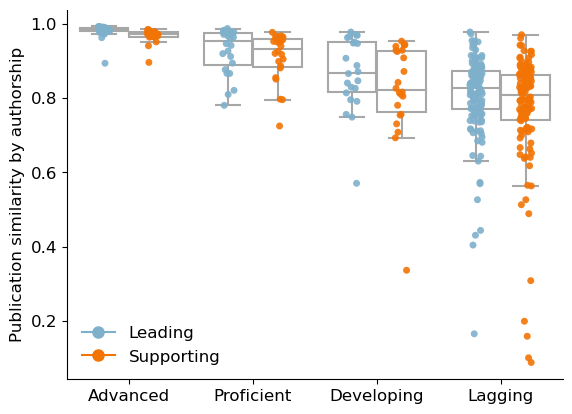

In [111]:
fig, ax=plt.subplots()
color={'L':'#7EB0CC','S':'#F27405'}
order = ['Advanced','Proficient','Developing','Lagging']
sns.stripplot(x='ST',y='similarity',data=cntry_type, hue='role', ax=ax, order=order,dodge=True, alpha=0.9, legend=False, palette=color)
sns.boxplot(x='ST',y='similarity',data=cntry_type, hue='role',
            boxprops={'facecolor':'none', 'edgecolor':'#A7A7A7'},
            medianprops={'color':'#A7A7A7'},
            whiskerprops={'color':'#A7A7A7'},
            capprops={'color':'#A7A7A7'},
            order=order,
            fliersize=0,
            ax=ax)


ax.set_ylabel("Publication similarity by authorship", fontsize=12)
ax.set_xlabel("")
ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

legend_markers = [plt.Line2D([0], [0], marker='o', color=color['L'], markerfacecolor=color['L'], markersize=8),
                  plt.Line2D([0], [0], marker='o', color=color['S'], markerfacecolor=color['S'], markersize=8)]
plt.legend(legend_markers, ['Leading', 'Supporting'], fontsize=12, frameon=False)
plt.savefig('../../data/dropbox/LaborDivision/figs/pub_similarity_derived_by_authorship.pdf',bbox_inches='tight')

In [104]:
cntry_groups = cntry_type[['cntry','ST']].drop_duplicates()
btsp = pd.DataFrame()
for i in range(20):
    cntry_sampled = cntry_groups.groupby(['ST']).sample(n=20, replace=True)['cntry']
    df_sampled = cntry_type[cntry_type.cntry.isin(cntry_sampled)]
    df_sampled = df_sampled.groupby(['ST','role'])['similarity'].mean().reset_index()
    btsp = pd.concat([btsp, df_sampled])
    

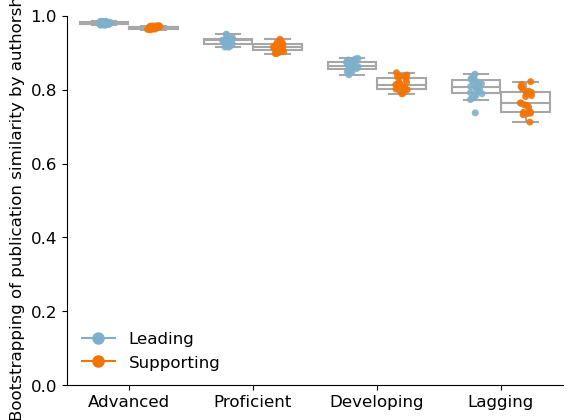

In [109]:
fig, ax=plt.subplots()
color={'L':'#7EB0CC','S':'#F27405'}
order = ['Advanced','Proficient','Developing','Lagging']
sns.stripplot(x='ST',y='similarity',data=btsp, hue='role', ax=ax, order=order,dodge=True, alpha=0.9, legend=False, palette=color)
sns.boxplot(x='ST',y='similarity',data=btsp, hue='role',
            boxprops={'facecolor':'none', 'edgecolor':'#A7A7A7'},
            medianprops={'color':'#A7A7A7'},
            whiskerprops={'color':'#A7A7A7'},
            capprops={'color':'#A7A7A7'},
            order=order,
            fliersize=0,
            ax=ax)


ax.set_ylabel("Bootstrapping of publication similarity by authorship", fontsize=12)
ax.set_xlabel("")
ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylim(0,1)

legend_markers = [plt.Line2D([0], [0], marker='o', color=color['L'], markerfacecolor=color['L'], markersize=8),
                  plt.Line2D([0], [0], marker='o', color=color['S'], markerfacecolor=color['S'], markersize=8)]
plt.legend(legend_markers, ['Leading', 'Supporting'], fontsize=12, frameon=False)
plt.savefig('../../data/dropbox/LaborDivision/figs/bootstrapping_pub_similarity_derived_by_authorship.pdf',bbox_inches='tight')

In [23]:
cnt = pub_all[pub_all.intl==1][['cluster_id','cntry','year']].drop_duplicates()

In [24]:
stgroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_group_meta.csv'
stgroup_df=pd.read_csv(stgroup_path)[['Code','ST']].drop_duplicates()
stgroup_df=stgroup_df.replace(to_replace={'ST':{'Others':'Lagging'}})
stgroup_df.head()

,Code,ST
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [27]:
cnt = cnt.merge(stgroup_df, left_on='cntry', right_on='Code')

In [32]:
(122729-23932)/23932

4.1282383419689115